In [1]:
#Data Preprocessing:
import glob
import pandas as pd
import numpy as np
import os as os
import matplotlib.pyplot as plt
#%matplotlib inline
from matplotlib import dates
#import warnings
#warnings.simplefilter("ignore")
import easygui as es

#Data Evaluation:
import statsmodels as st
#from statsmodels.tsa.filters.hp_filter import hpfilter
#from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm
from statsmodels.tsa.stattools import acovf,acf,pacf,pacf_yw,pacf_ols
from pandas.plotting import lag_plot
#from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
#from statsmodels.tsa.statespace.tools import diff
from statsmodels.tsa.stattools import ccovf,ccf
from statsmodels.tsa.arima_process import arma_periodogram #trying to fix library
from statsmodels.tsa.stattools import adfuller,kpss,coint,bds,q_stat,grangercausalitytests,levinson_durbin
from statsmodels.graphics.tsaplots import month_plot,quarter_plot
import matplotlib.ticker as ticker

#Model Selection:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.ar_model import AR,ARResults
from pmdarima import auto_arima
from statsmodels.tsa.stattools import arma_order_select_ic
from statsmodels.tsa.arima_model import ARMA,ARMAResults,ARIMA,ARIMAResults
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX, VARMAXResults

#Model Evaluation & Forecasting:
from statsmodels.tools.eval_measures import mse, rmse, meanabs
from sklearn.metrics import mean_squared_error

In [2]:
#Setup dir and look at it.
os.chdir(r"/Users/iheredia/OneDrive - CINVESTAV/DataspellProjects/pythonc310Project/forecast")
for file in glob.glob('./*'):
    print(file)

./README.md
./online_retail.xlsx
./Forecast_sales.ipynb


In [3]:
#Load data and explore:
df = pd.read_excel("online_retail.xlsx", engine='openpyxl') #,parse_dates = True
df.head(5)

,Month,Sales
0,1992-01-01,3459
1,1992-02-01,3458
2,1992-03-01,4002
3,1992-04-01,4564
4,1992-05-01,4221


In [4]:
df.tail(5)

,Month,Sales
320,2018-09-01,12396
321,2018-10-01,13914
322,2018-11-01,14174
323,2018-12-01,15504
324,2019-01-01,10718


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Month   325 non-null    datetime64[ns]
 1   Sales   325 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 5.2 KB


In [6]:
df.describe()

,Month,Sales
count,325,325.000000
mean,2005-07-01 13:35:15.692307712,7886.400000
min,1992-01-01 00:00:00,3031.000000
25%,1998-10-01 00:00:00,5231.000000
50%,2005-07-01 00:00:00,7481.000000
75%,2012-04-01 00:00:00,9977.000000
max,2019-01-01 00:00:00,15504.000000
std,NaN,2914.269061


In [7]:
# Date is already a datetime64[ns] with correct formar, so no need to convert.
#df["Month"]  =  pd.to_datetime(df["Month"], format='%Y-%m-%d')
#df.info()

In [8]:
#Dropping NA's (just in case!):
df = df.dropna()

In [9]:
#Set the Datetime field as the index field and
df.set_index("Month",inplace=True)

In [10]:
# Set index frequency: https://pandas.pydata.org/docs/user_guide/timeseries.html#timeseries-offset-aliases
# Will use calendar month begin (MS)
print(df.index.freq)
df.index.freq = 'MS'
print(df.index.freq)

None
<MonthBegin>


In [11]:
# Check...
df.tail(2)

,Sales
Month,
2018-12-01,15504
2019-01-01,10718


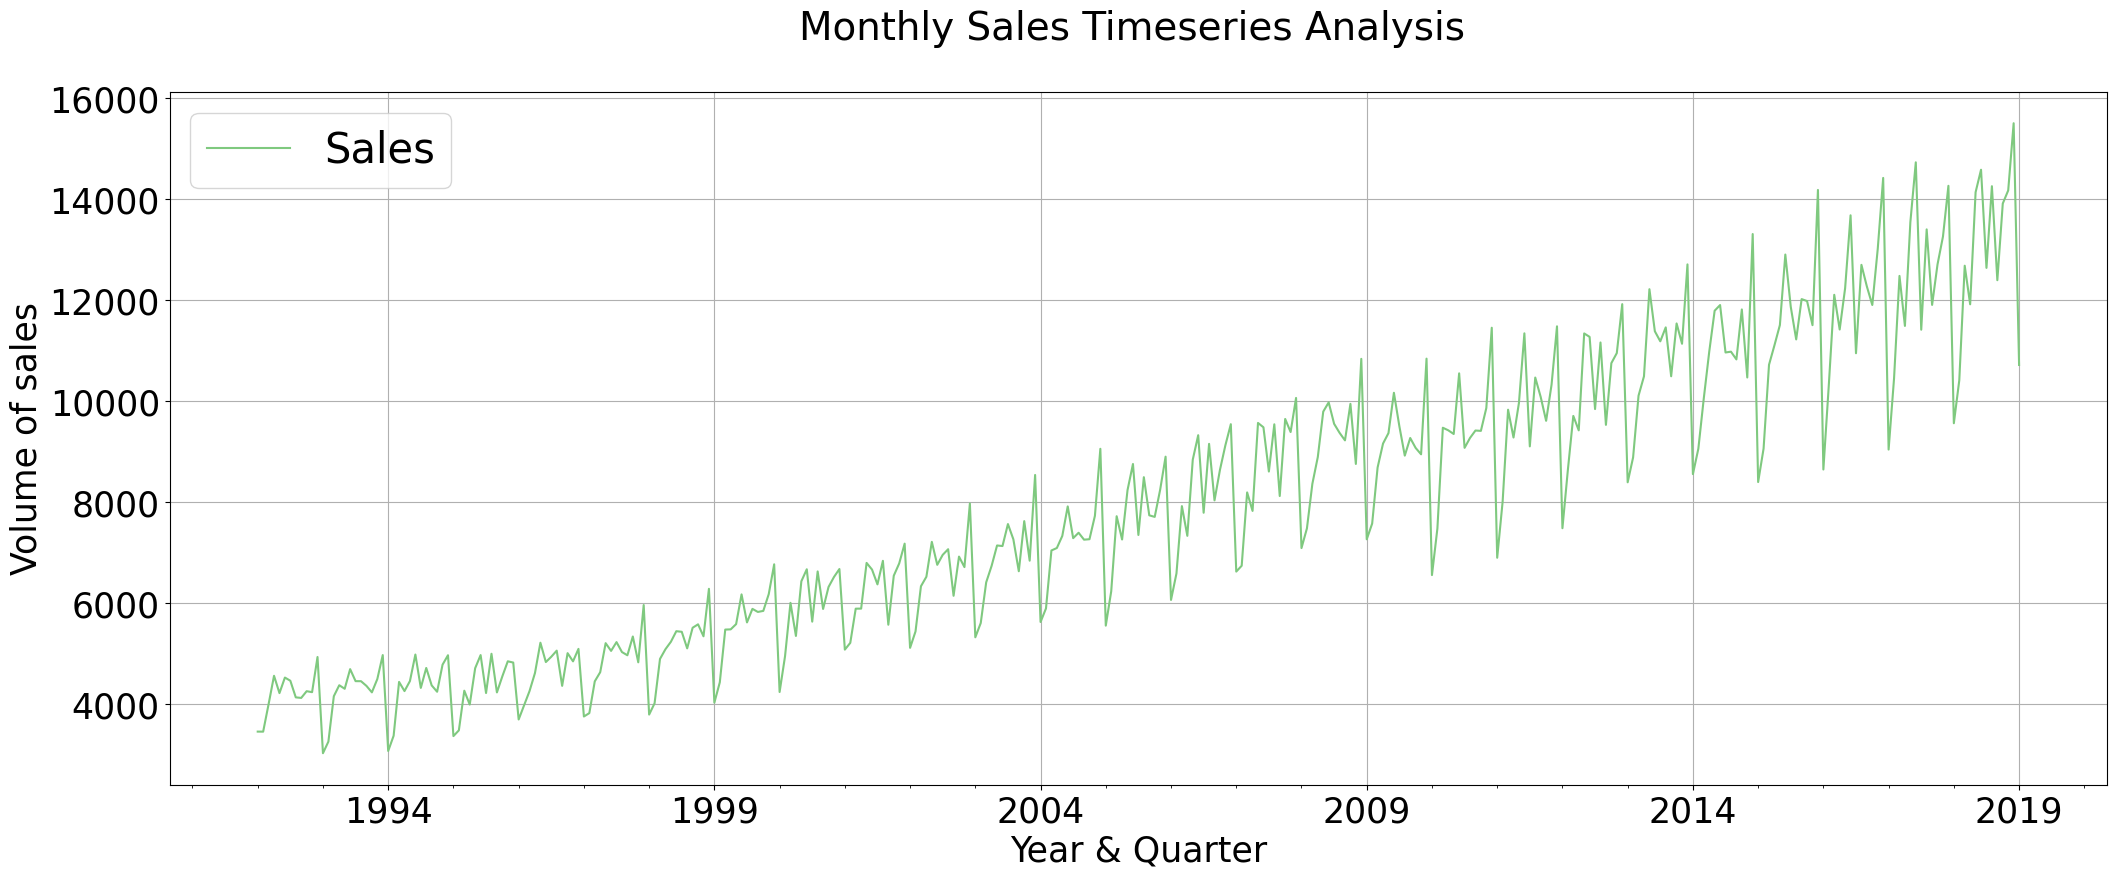

In [12]:
#Plot Timeseries:
ax =  df['Sales'].plot(legend =True, table = False, grid = True, subplots = False, figsize =(25,9), fontsize = 25, colormap = 'Accent', linestyle='-', stacked=False)
plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.title('Monthly Sales Timeseries Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)

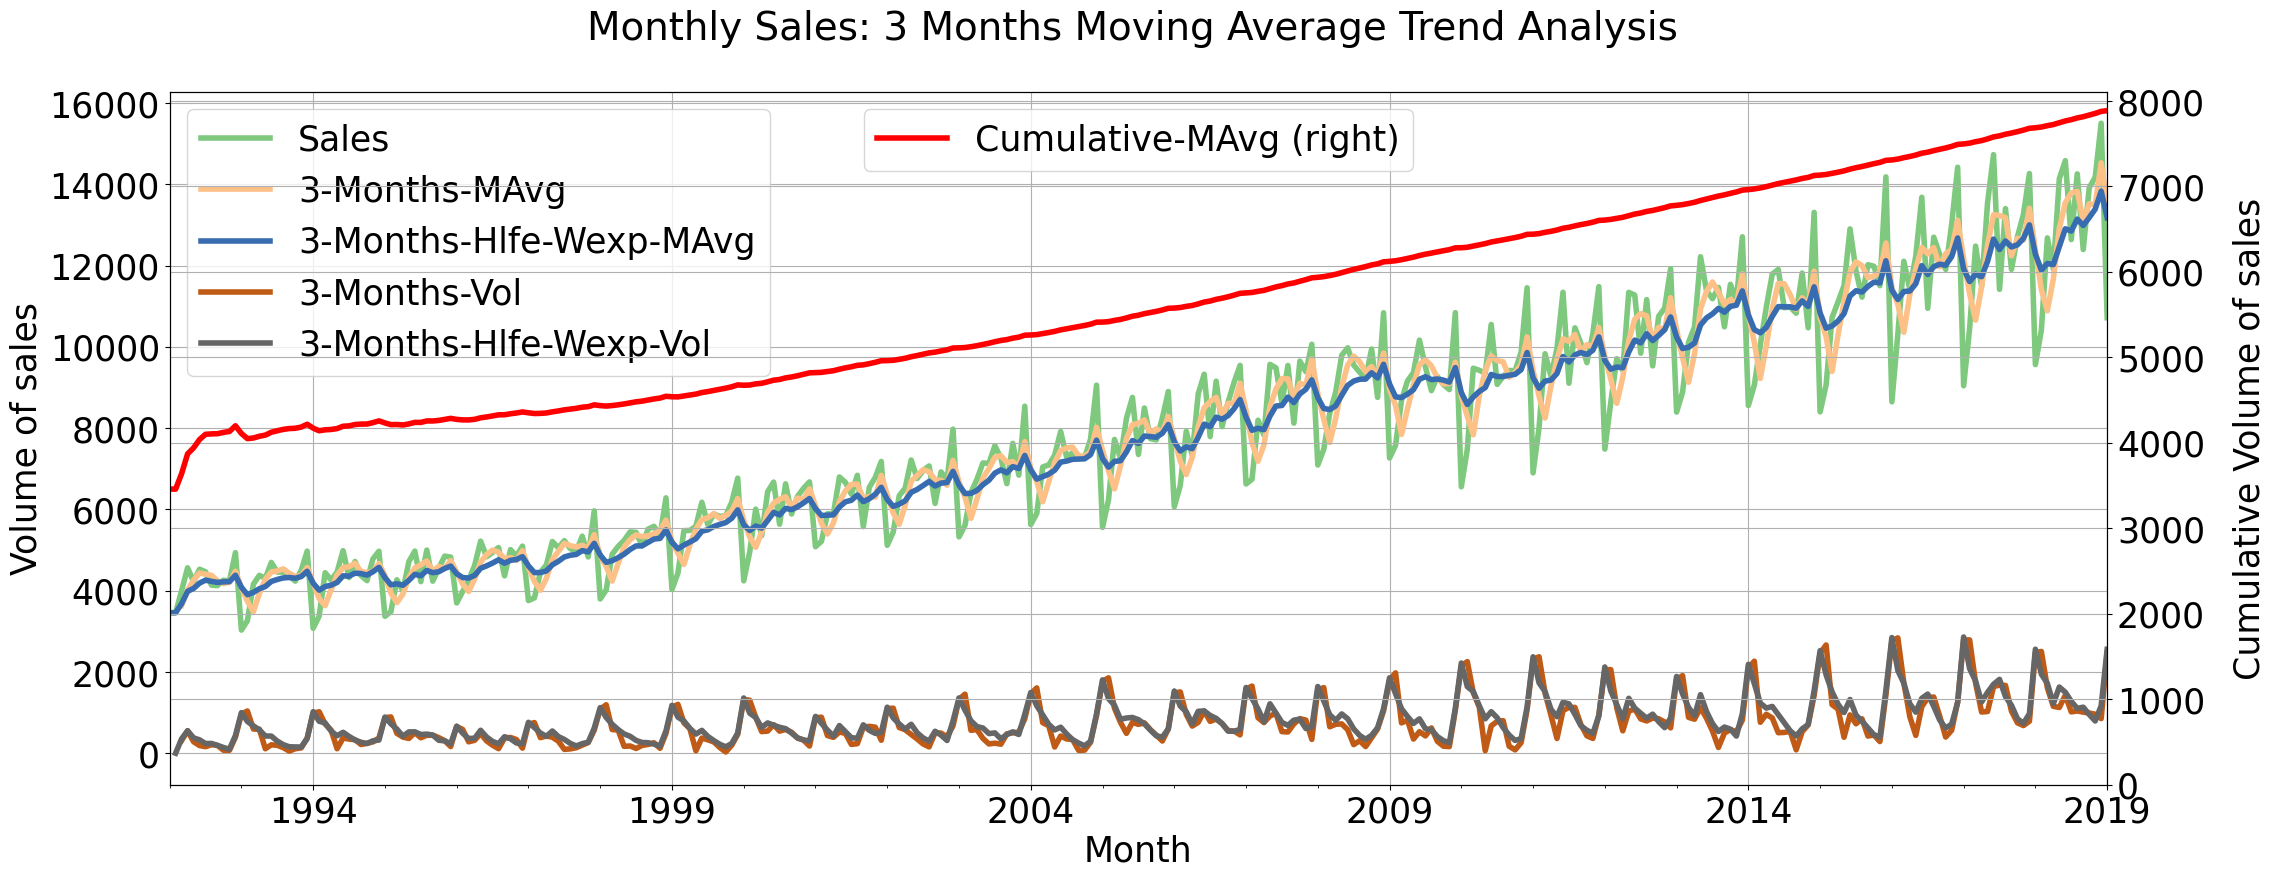

In [13]:
# Simple Moving Average Trend Analysis
#   --> help to identify areas of support ad resistance.
#   --> filters out random noise / smoothes out fluctuations.

# Windowing (group) every 3 months to smooth series and find volatility.
df["3-Months-MAvg"] = df["Sales"].rolling(window=3).mean()
df['3-Months-Vol'] = df['Sales'].rolling(window=3).std()

# Also try exponential weighted moving average:
df['3-Months-Hlfe-Wexp-MAvg'] = df["Sales"].ewm(halflife="90 days", times=df.index).mean()
df['3-Months-Hlfe-Wexp-Vol'] = df["Sales"].ewm(halflife="90 days", times=df.index).std()

# And cumulative (all previous points w/o weighting) moving average
df['Cumulative-MAvg'] = df['Sales'].expanding().mean()

plt.figure(figsize=(25,9))
plt.title('Monthly Sales: 3 Months Moving Average Trend Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
ax = plt.gca() #get current axis
ax.set_xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")

# Plot moving averages and volatility:
ax1 =  df[['Sales', '3-Months-MAvg','3-Months-Hlfe-Wexp-MAvg','3-Months-Vol','3-Months-Hlfe-Wexp-Vol']].plot(fontsize = 25, table = False, grid = True, subplots = False, colormap = 'Accent', linestyle='-', stacked=False, linewidth = 4, ax=ax)

# Plot cumulative average
ax2 = df[['Cumulative-MAvg']].plot(fontsize = 25, table = False, grid = True, subplots = False, linestyle='-', stacked=False, linewidth = 4, color='r', ax=ax, secondary_y = True)
ax1.set_ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax2.set_ylabel('Cumulative Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif", labelpad=20)
ax2.set_ylim(ymin=0)

ax1.legend(loc="upper left", fontsize = 25)
ax2.legend(loc="upper center", fontsize = 25)
plt.xticks(rotation=0, horizontalalignment="center")
#plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=True)

From the rolling 3-months moving averages trendlines:
 --> Sales trends up around the mid of every quarter
 --> Band of resistance towards the end of the very same quarter.
 --> Band of support occurs before the wave of resistance in every quarter.

From the volatility:
 --> Slightly increases with time, hinting non-stationarity.

From Cumulative average:
 --> Average across history, lows and highs.
 --> Slightly increase with time, so company grows slowly but constant.

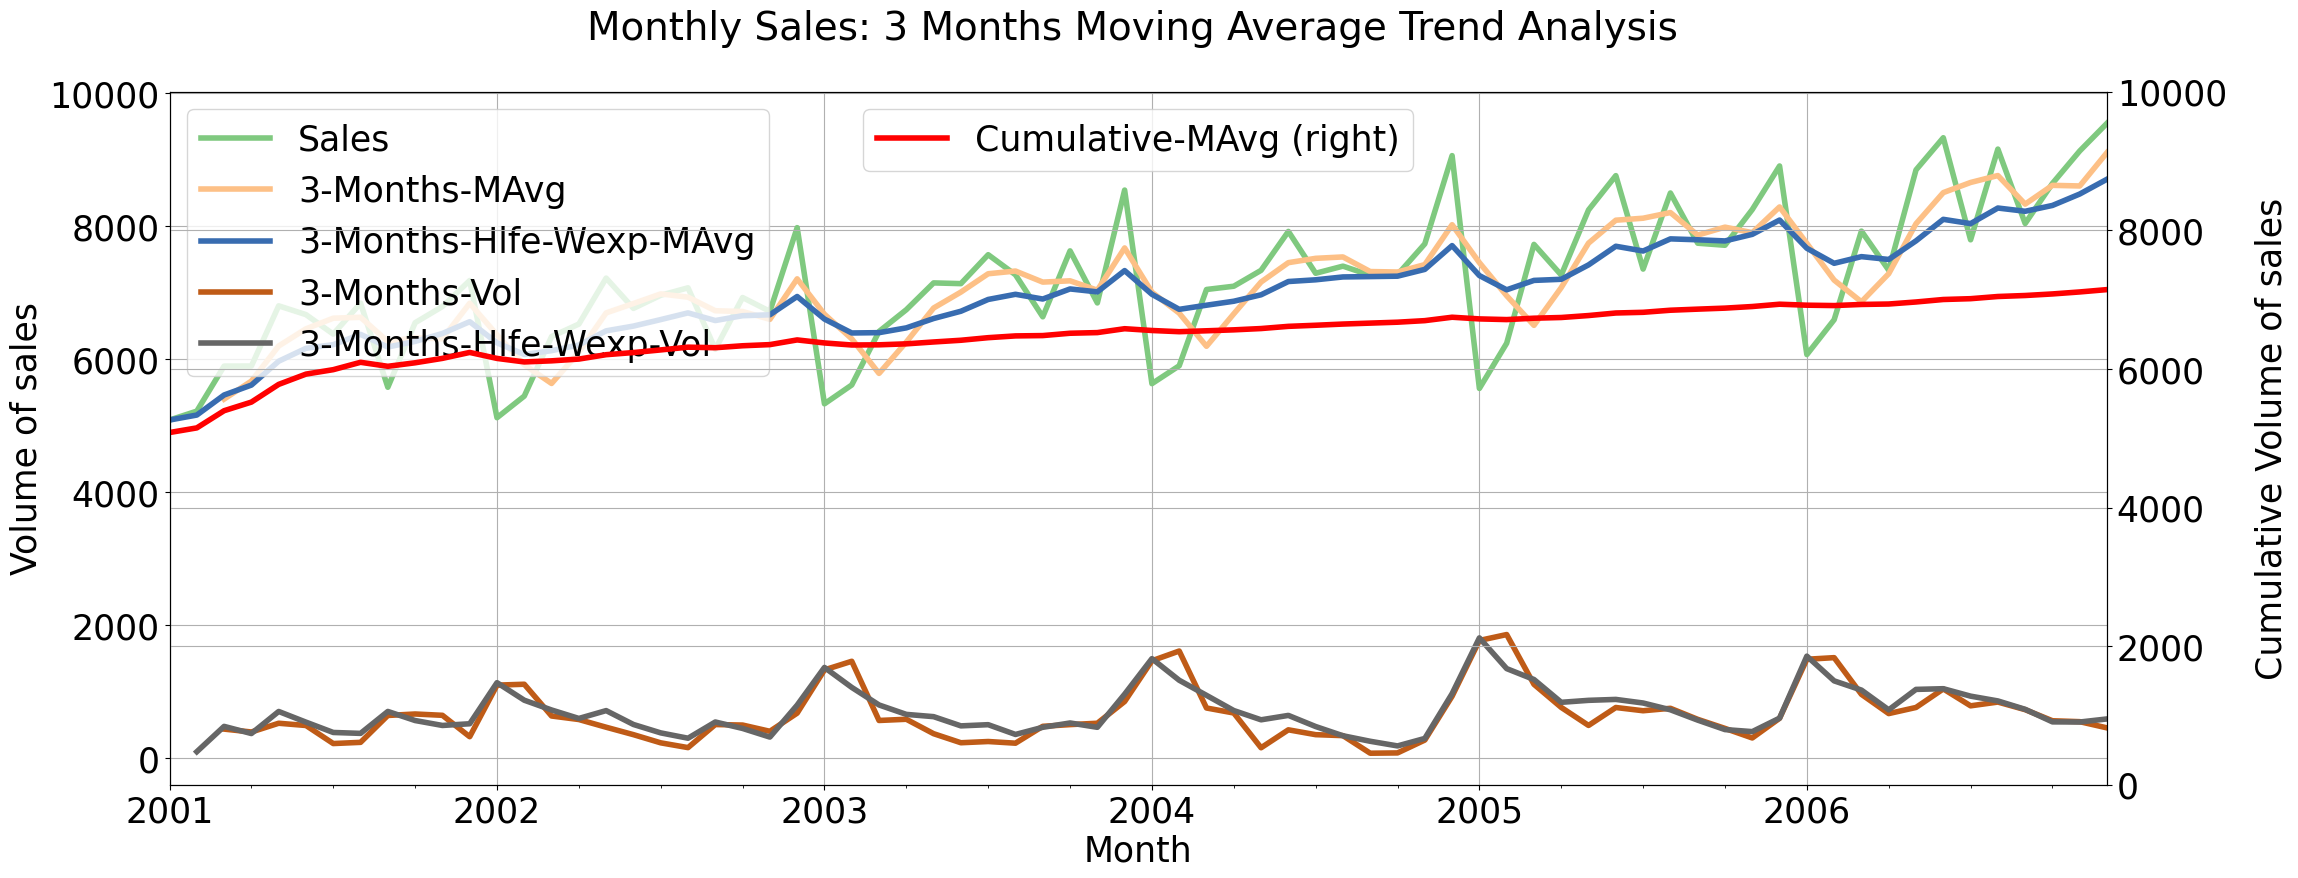

In [14]:
# Let's repeat the plot in a smaller interval to make the previous observations
# more obvious.
selector = (df.index.year>=2001) & (df.index.year<2007)
df_small = df[selector].copy()

df_small["3-Months-MAvg"] = df_small["Sales"].rolling(window=3).mean()
df_small['3-Months-Vol'] = df_small['Sales'].rolling(window=3).std()
df_small['3-Months-Hlfe-Wexp-MAvg'] = df_small["Sales"].ewm(halflife="90 days", times=df_small.index).mean()
df_small['3-Months-Hlfe-Wexp-Vol'] = df_small["Sales"].ewm(halflife="90 days", times=df_small.index).std()
df_small['Cumulative-MAvg'] = df_small['Sales'].expanding().mean()

plt.figure(figsize=(25,9))
plt.title('Monthly Sales: 3 Months Moving Average Trend Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
ax = plt.gca() #get current axis
ax.set_xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax1 = df_small[['Sales', '3-Months-MAvg','3-Months-Hlfe-Wexp-MAvg','3-Months-Vol','3-Months-Hlfe-Wexp-Vol']].plot(fontsize = 25, table = False, grid = True, subplots = False, colormap = 'Accent', linestyle='-', stacked=False, linewidth = 4, ax=ax)
ax2 = df_small[['Cumulative-MAvg']].plot(fontsize = 25, table = False, grid = True, subplots = False, linestyle='-', stacked=False, linewidth = 4, color='r', ax=ax, secondary_y = True)
ax1.set_ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax2.set_ylabel('Cumulative Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif", labelpad=20)
ax2.set_ylim(ymin=0,ymax=10000)
ax1.legend(loc="upper left", fontsize = 25)
ax2.legend(loc="upper center", fontsize = 25)
plt.xticks(rotation=0, horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

The Hodrick–Prescott filter (also known as Hodrick–Prescott decomposition) is used in macroeconomics, especially in real business cycle theory, to remove the cyclical component of a time series from raw data.

It is used to obtain a smoothed-curve representation of a time series, one that is more sensitive to long-term than to short-term fluctuations.

The adjustment of the sensitivity of the trend to short-term fluctuations is achieved by modifying a multiplier \lambda .

It is a special case of a smoothing spline.

If x_t is the original series,
  y_t = ln(x_t) = tau_t (trend comp.) + c_t (cyclical comp.) + eps_t (error comp.)
  --> To isolate trend component, find tau_t that minimizes sum_t(y_t - tau_t) ==> penalizes cyclical component.
    --> To isolate cyclical component, tau_t is also required to minimize lambda * [(tau_t+1 + tau_t) + (tau_t - tau_t-1) ]^2 ==> lambda gauges the penalization on the increase of the trend component.
       --> lambda ~ 1600 for quarterly data. In practice, lambda ~ 100 for yearly data, and ~ 14,400 for monthly data.

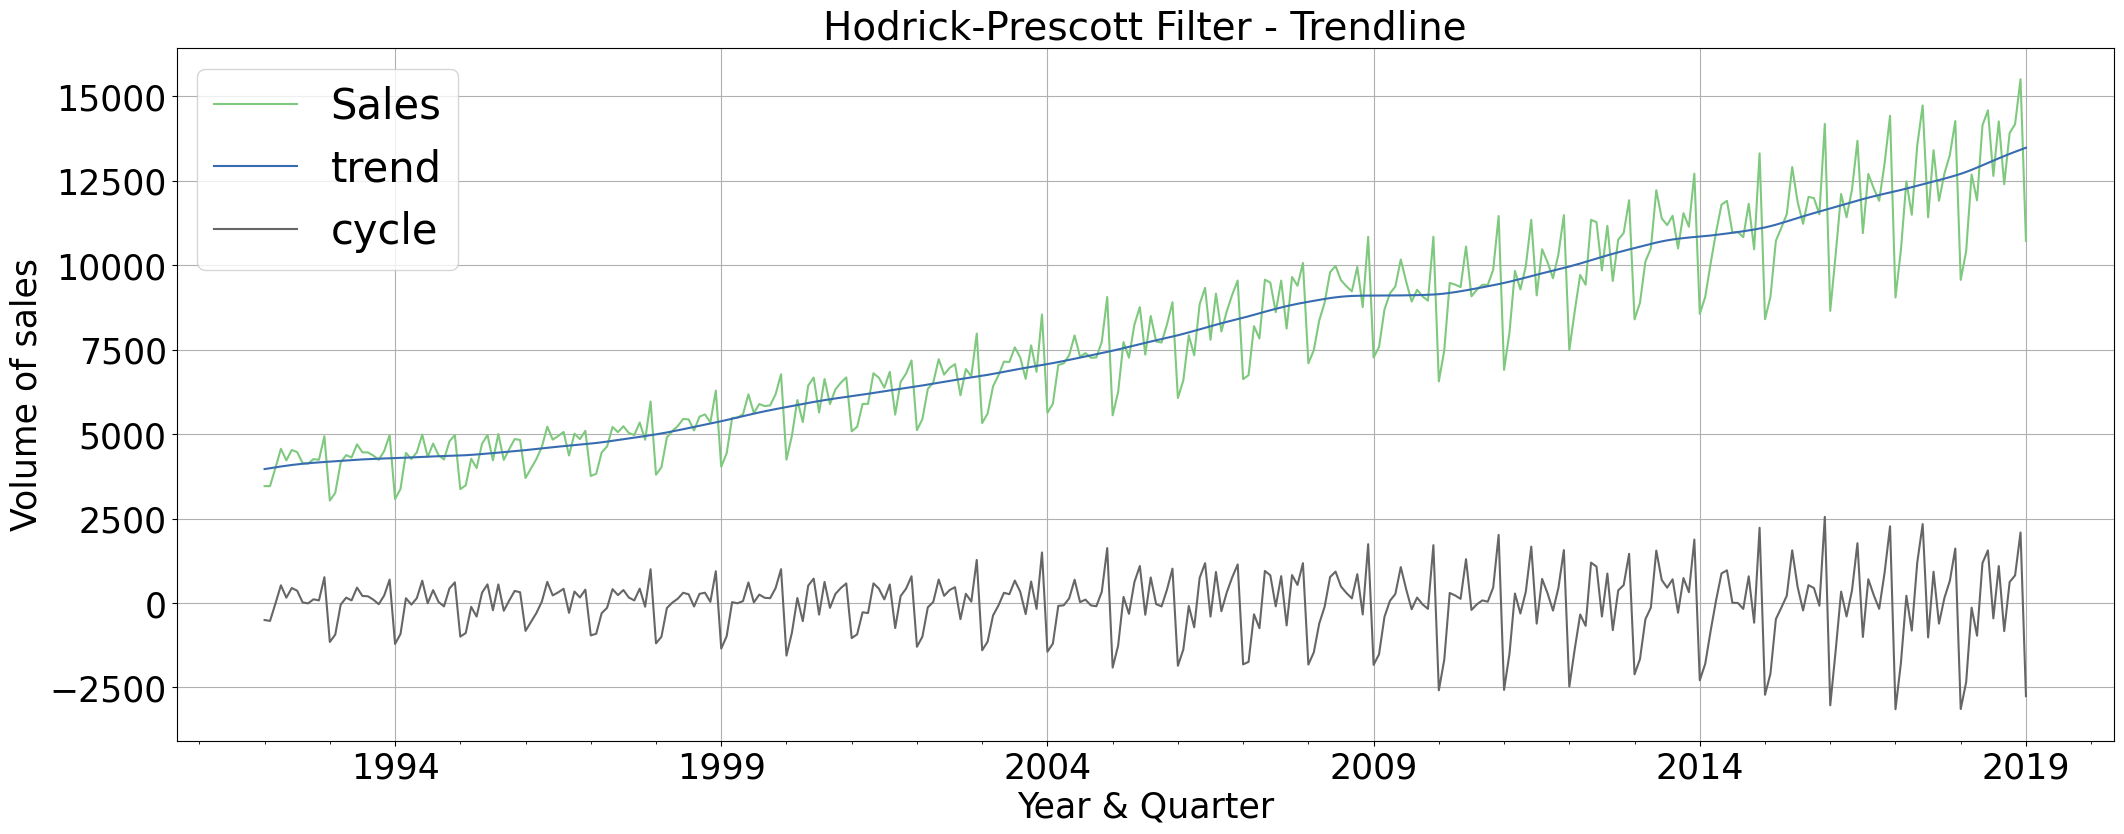

In [15]:
# Hodrick-Prescott Filter:

# Extract cyclical and trend components:
sales_cycle, sales_trend = st.tsa.filters.hp_filter.hpfilter(df["Sales"], lamb = 1600)
df["cycle"] = sales_cycle
df["trend"] = sales_trend

# Plot timeseries and components:
ax =  df[["Sales","trend","cycle"]].plot(legend =True, table = False, grid = True, subplots = False, figsize =(25,9), fontsize = 25, colormap = 'Accent', linestyle='-', stacked=False)
plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.title('Hodrick-Prescott Filter - Trendline',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)


The trendline confirms an overall growth pattern at a non-linear rate over the course of time.

Now, a more serious analysis would separate a time-series in:
   - three systematic components (can be modeled): level, trend, seasonality.
   - one non-systematic component:  noise/error/residual.

Level: The average value in the series --> Really, just the average.
Trend: The increasing or decreasing value in the series --> hpfilter --> in this context, trend can include "a cyclical", but not seasonal (repetitive) component.
Seasonality: The repeating short-term cycle in the series --> really is the repetitive component --> ETS decomposition.
Noise: The random variation in the series. --> ETS decomposition.

Let's isolate systematic & non-systematic components.

Since sales increase seems to be non-linear, "a 'multiplicative' model is appropiate".
 --> Otherwise, when seasonality and trend components are constant over time, apply "an 'additive' model".

ETS (Error-Trend-Seasonality) decompsition by: https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html
 --> This is a naive decomposition. More sophisticated methods should be preferred.
 --> The additive model is Y[t] = T[t] + S[t] + e[t]
 --> The multiplicative model is Y[t] = T[t] * S[t] * e[t]

The results are obtained by first estimating the trend by applying a convolution filter to the data. The trend is then removed from the series and the average of this de-trended series for each period is the returned seasonal component.



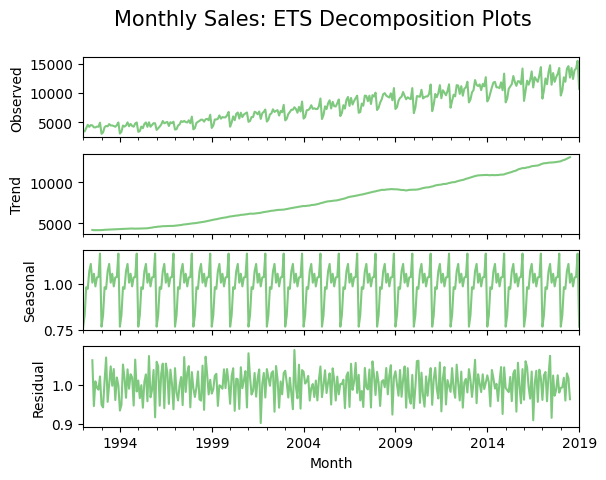

In [16]:
result = st.tsa.seasonal.seasonal_decompose(df["Sales"]
                            , model = "multiplicative")
fig, axes = plt.subplots(4, 1, sharex=True)
fig.suptitle("Monthly Sales: ETS Decomposition Plots",horizontalalignment="center", fontstyle = "normal", fontsize = "15", fontfamily = "sans-serif")
result.observed.plot(ax=axes[0], legend=False, colormap = 'Accent')
axes[0].set_ylabel('Observed')
result.trend.plot(ax=axes[1], legend=False, colormap = 'Accent')
axes[1].set_ylabel('Trend')
result.seasonal.plot(ax=axes[2], legend=False, colormap = 'Accent')
axes[2].set_ylabel('Seasonal')
result.resid.plot(ax=axes[3], legend=False, colormap = 'Accent')
axes[3].set_ylabel('Residual')
ax.autoscale(enable=True, axis='x', tight=False)

Let's check seasonality by taking lags, which are linear regressions between x_t and x_t-k , where k = 1,2,3,... If there is a period, the correlation should be periodic.

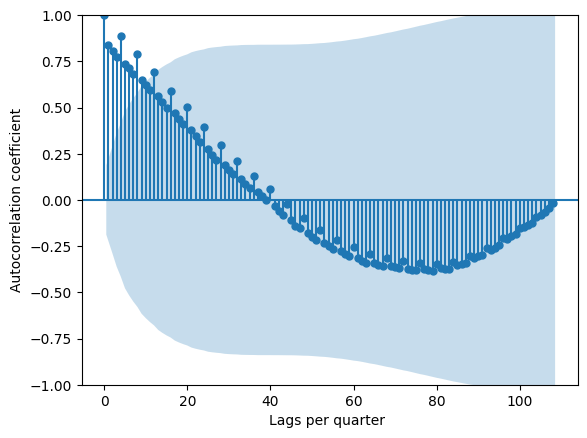

In [51]:
fig, ax = plt.subplots()
st.graphics.tsaplots.plot_acf(df.asfreq(freq ='3MS')["Sales"],lags=108, alpha=0.05,ax=ax) #(df.shape[0]-1)
ax.set_ylabel("Autocorrelation coefficient")
ax.set_xlabel("Lags per quarter ")
#labels = ["Year " + str(i) for i in range(int(365*3/365))] #df.shape[0]
#plt.xticks(ticks=range(0,df.asfreq(freq ='3MS').shape[0],4)) #,labels=labels
plt.title("")
ax.autoscale(enable=True, axis='x', tight=False)
plt.show()

Correlation is lost every ~40*4/12 ~ 13 years, is periodic every year, and is significant for ~ 2 years.

** Therefore, we can confirm that the timseries is NOT stationary.

Two more test of NOT stationarity:
  - The Augmented Dickey-Fuller test for stationarity takes null hypothesis H0 for a nonstationary timeseries. Alternate hypothesis H1 supports stationarity with a small p-value ( p<0.05 ).
  - KPSS (Kwiatkowski-Phillips-Schmidt-Shin) Test results are directly opposite to that of the ADF test when it comes to interpreting the null and alternate hypothesis.

In [57]:
def adf_test(series,title=''):
    print(f'Augmented Dickey-Fuller Test: {title}')
    result = adfuller(series.dropna(),autolag='AIC') #.dropna() handles differenced data
    # fill first 4 indices
    labels = ['ADF test statistic','p-value','# lags used','# observations']
    out = pd.Series(result[0:4],index=labels)
    # fill 5th index by hand (critical values)
    for key,val in result[4].items():
        out[f'critical value ({key})']=val
    print(out.to_string())          # .to_string() removes the line "dtype: float64"
    if result[1] <= 0.05:
        print("Strong evidence against the null hypothesis")
        print("Reject the null hypothesis")
        print("Data has no unit root and is stationary")
    else:
        print("Weak evidence against the null hypothesis")
        print("Fail to reject the null hypothesis")
        print("Data has a unit root and is non-stationary")

def kpss_test(timeseries):
    print ('Results of KPSS Test:')
    kpsstest = kpss(timeseries, regression='c')
    kpss_output = pd.Series(kpsstest[0:3], index=
    ['Test Statistic','p-value','Lags Used'])
    for key,value in kpsstest[3].items():
        kpss_output['Critical Value (%s)'%key] = value
        print (kpss_output)


In [55]:
adf_test(df["Sales"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic        2.037405
p-value                   0.998720
# lags used              14.000000
# observations          310.000000
critical value (1%)      -3.451622
critical value (5%)      -2.870909
critical value (10%)     -2.571762
Weak evidence against the null hypothesis
Fail to reject the null hypothesis
Data has a unit root and is non-stationary


In [58]:
kpss_test(df["Sales"])

Results of KPSS Test:
Test Statistic           2.79443
p-value                  0.01000
Lags Used               11.00000
Critical Value (10%)     0.34700
dtype: float64
Test Statistic           2.79443
p-value                  0.01000
Lags Used               11.00000
Critical Value (10%)     0.34700
Critical Value (5%)      0.46300
dtype: float64
Test Statistic            2.79443
p-value                   0.01000
Lags Used                11.00000
Critical Value (10%)      0.34700
Critical Value (5%)       0.46300
Critical Value (2.5%)     0.57400
dtype: float64
Test Statistic            2.79443
p-value                   0.01000
Lags Used                11.00000
Critical Value (10%)      0.34700
Critical Value (5%)       0.46300
Critical Value (2.5%)     0.57400
Critical Value (1%)       0.73900
dtype: float64


/var/folders/px/hp6xtxyn7vl1zq8_k8x1f5kw0000gn/T/ipykernel_27764/3207214412.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpsstest = kpss(timeseries, regression='c')


Now that we are convinced of non-stationarity (Sales depends on t), Partial Auto Correlation (PACF) Plots can be generated.
--> A partial autocorrelation is the amount of correlation between a variable and a lag of itself that is not explained by correlations at all lower-order-lags.
   --> partial auto-correlation between x_t and x_t-k removes the contribution to the correlation due to other lags x_t-l, for l = 1,2,..,k-1.
 https://en.wikipedia.org/wiki/Partial_autocorrelation_function
   --> For an "Autoregressive "  model (AR), one examines the PACF plots to find the lag after which the partial autocorrelations are all within the confidence interval. This lag is determined to likely be the AR model's order.
   --> That is, the autocorrelations are significant for a large number of lags--but perhaps the autocorrelations at lags 2 and above are merely due to the propagation of the autocorrelation at lag 1. This can be confirmed by the PACF plot.


Now, forecasting requires working with simpler timeseries, which can be obtained from the original, for instance, by defining x_t' = x_t - x_t-1 = x_t - L(x_t) = (1-L)x_t or "FIRST DIFFERENTATION". (equivalent to daily returns of stocks).
    --> If x_t' = eps = white noise, x_t' is a random walk (unpredictable).
    --> "Nth-order differentiation" (e.g. x_t'' = x_t' - x_t-1') is shown to be x_t^(N) = (1-L)^N x_t.





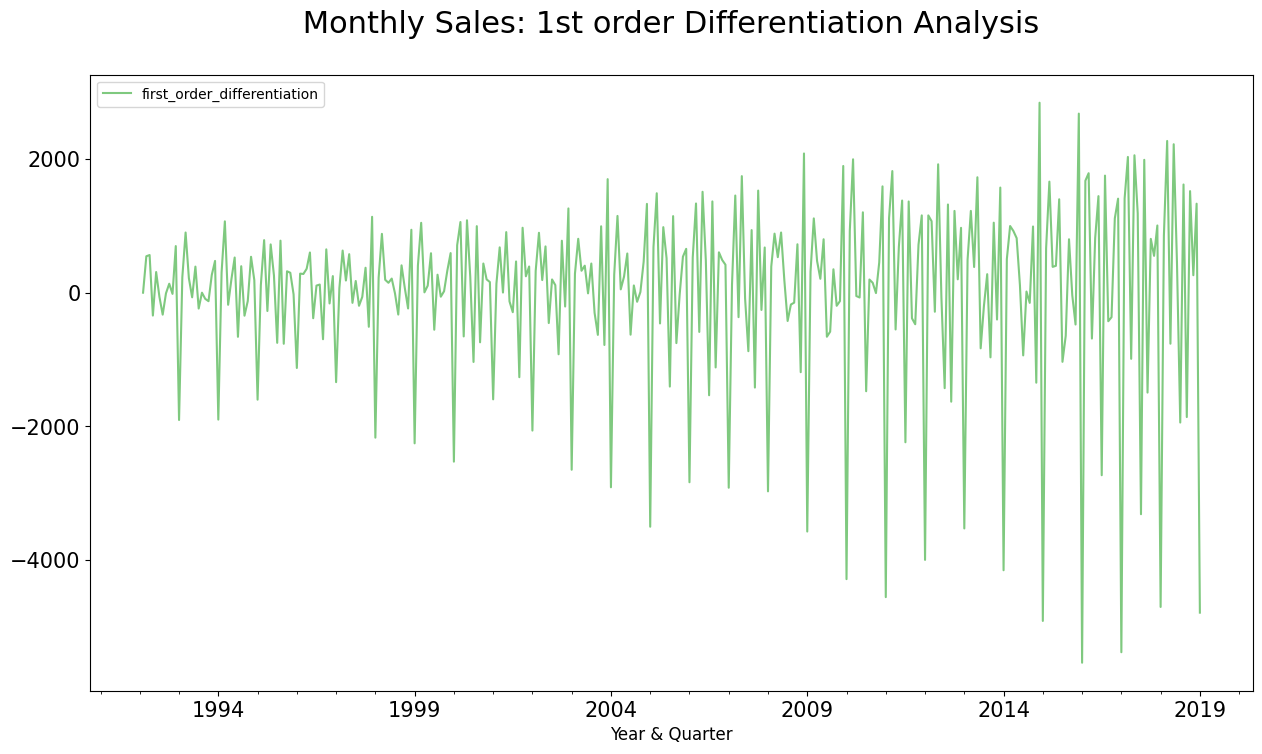

In [61]:
df["first_order_differentiation"] = st.tsa.statespace.tools.diff(df["Sales"], k_diff = 1)


#Plot the Graph:

ax =  df["first_order_differentiation"].plot(title = 'Monthly Sales Timeseries Data : 1st order Differentiation' , legend =True, table = False, grid = False , subplots = False,  figsize =(15,8) , colormap = 'Accent', fontsize = 15 ,linestyle='-', stacked=False)

#Configure x and y labels:

#plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")

#Set up title, legends and theme:

plt.title(' Monthly Sales: 1st order Differentiation Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
#plt.style.use(['classic'])
ax.autoscale(enable=True, axis='x', tight=False)
